1. BUSCO PUNTOS CRITICOS
2. LINEALIZO EN ESO PUNTOS CRITICOS
3. ESCRIBO LA JACOBIANA
4. JACOBIANA EVALLUADA EN 0 ME DA LA MATRIZ A
5. BUSCO AUTOVALORES = ME DEBERIA HABER QUEDADO LA MATRIZ DIAGONAL CON LSO DOS AUTOVALORES. 

los autovalores positivos ya me hablan de sistema INESTABLE

ESTARIA BUENO APRENDER A IDENTIFICAR EL INICIO DE LOS VECTORES EL CAMPO Y EL FINAL 

puedo usarr directamnete la funcion que me da el jacobiano



## Ejercicio 1 — Análisis de estabilidad

Consideramos el siguiente sistema dinámico no lineal:

$$
\dot{x}=x(a-by)
$$

$$
\dot{y}=y(-c+dx)
$$

El objetivo es:

1. Encontrar los puntos críticos del sistema.
2. Calcular la matriz Jacobiana.
3. Evaluar la matriz Jacobiana en cada punto crítico.
4. Obtener los autovalores.
5. Determinar la estabilidad de cada punto crítico.

---

### 1. Puntos críticos

Los puntos críticos se obtienen imponiendo que ambas derivadas sean nulas:

$$
\dot{x}=0
$$

$$
\dot{y}=0
$$

Por lo tanto:

$$
x(a-by)=0
$$

$$
y(-c+dx)=0
$$

De estas ecuaciones se obtienen los siguientes puntos críticos:

$$
P_1=(0,0)
$$

y

$$
P_2=\left(\frac{c}{d},\frac{a}{b}\right)
$$

suponiendo $b\neq0$ y $d\neq0$.

---

### 2. Matriz Jacobiana

Definimos:

$$
f(x,y)=x(a-by)
$$

$$
g(x,y)=y(-c+dx)
$$

La matriz Jacobiana del sistema es:

$$
J(x,y)=
\begin{pmatrix}
\frac{\partial f}{\partial x} &
\frac{\partial f}{\partial y}\\
\frac{\partial g}{\partial x} &
\frac{\partial g}{\partial y}
\end{pmatrix}
$$

Calculando las derivadas parciales:

$$
\frac{\partial f}{\partial x}=a-by
$$

$$
\frac{\partial f}{\partial y}=-bx
$$

$$
\frac{\partial g}{\partial x}=dy
$$

$$
\frac{\partial g}{\partial y}=-c+dx
$$

Por lo tanto:

$$
J(x,y)=
\begin{pmatrix}
a-by & -bx\\
dy & -c+dx
\end{pmatrix}
$$

---

### 3. Análisis del punto crítico $(0,0)$

Evaluamos la matriz Jacobiana en $(0,0)$:

$$
J(0,0)=
\begin{pmatrix}
a & 0\\
0 & -c
\end{pmatrix}
$$

Los autovalores son:

$$
\ lambda_1=a
$$

$$
\lambda_2=-c
$$

Si $a>0$ y $c>0$, entonces tenemos un autovalor positivo y otro negativo.

Por lo tanto, el punto $(0,0)$ es un **punto silla** y es **inestable**.

El sistema linealizado alrededor de este punto queda:

$$
\dot{x}=ax
$$

$$
\dot{y}=-cy
$$

---

### 4. Análisis del punto crítico $\left(\frac{c}{d},\frac{a}{b}\right)$

Evaluamos la matriz Jacobiana:

$$
J\left(\frac{c}{d},\frac{a}{b}\right)
=
\begin{pmatrix}
0 & -\frac{bc}{d}\\
\frac{ad}{b} & 0
\end{pmatrix}
$$

El polinomio característico es:

$$
\lambda^2+ac=0
$$

Por lo tanto:

$$
\lambda_{1,2}=\pm i\sqrt{ac}
$$

Los autovalores son complejos conjugados con parte real igual a cero.

Por lo tanto, el punto crítico es un **centro** y presenta estabilidad en el sentido de Lyapunov, pero no es asintóticamente estable.

---

### 5. Conclusión

Los puntos críticos del sistema son:

$$
(0,0)
$$

y

$$
\left(\frac{c}{d},\frac{a}{b}\right)
$$

Para $a>0$ y $c>0$:

- $(0,0)$ → **punto silla, inestable**.
- $\left(\frac{c}{d},\frac{a}{b}\right)$ → **centro, estable**.


In [1]:
import sympy as sp

# Variables
x, y = sp.symbols('x y')

# Parámetros del sistema
a, b, c, d = sp.symbols('a b c d', nonzero=True)

# Sistema dinámico
f = x * (a - b*y)
g = y * (-c + d*x)

# --------------------------------------------------
# 1. Puntos críticos
# --------------------------------------------------

# Resolver f = 0 y g = 0
puntos_criticos = sp.solve(
    [sp.Eq(f, 0), sp.Eq(g, 0)],
    [x, y],
    dict=True
)

print("Puntos críticos:")
for punto in puntos_criticos:
    print(punto)

Puntos críticos:
{x: 0, y: 0}
{x: c/d, y: a/b}


In [2]:
# --------------------------------------------------
# 2. Matriz Jacobiana
# --------------------------------------------------

J = sp.Matrix([
    [sp.diff(f, x), sp.diff(f, y)],
    [sp.diff(g, x), sp.diff(g, y)]
])

print("Matriz Jacobiana:")
sp.pretty_print(J)

Matriz Jacobiana:
⎡a - b⋅y    -b⋅x  ⎤
⎢                 ⎥
⎣  d⋅y    -c + d⋅x⎦


In [3]:
# --------------------------------------------------
# 3. Autovalores en cada punto crítico
# --------------------------------------------------

for i, punto in enumerate(puntos_criticos, start=1):

    J_punto = J.subs(punto)

    print(f"\nPunto crítico {i}:")
    print(punto)

    print("\nJacobiana evaluada:")
    sp.pretty_print(J_punto)

    print("\nAutovalores:")
    autovalores = J_punto.eigenvals()

    for valor, multiplicidad in autovalores.items():
        print(f"λ = {valor}   multiplicidad = {multiplicidad}")


Punto crítico 1:
{x: 0, y: 0}

Jacobiana evaluada:
⎡a  0 ⎤
⎢     ⎥
⎣0  -c⎦

Autovalores:
λ = a   multiplicidad = 1
λ = -c   multiplicidad = 1

Punto crítico 2:
{x: c/d, y: a/b}

Jacobiana evaluada:
⎡     -b⋅c ⎤
⎢ 0   ─────⎥
⎢       d  ⎥
⎢          ⎥
⎢a⋅d       ⎥
⎢───    0  ⎥
⎣ b        ⎦

Autovalores:
λ = -sqrt(-a*c)   multiplicidad = 1
λ = sqrt(-a*c)   multiplicidad = 1


Puntos críticos:
P1 = (0, 0)
P2 = (1.0, 1.0)


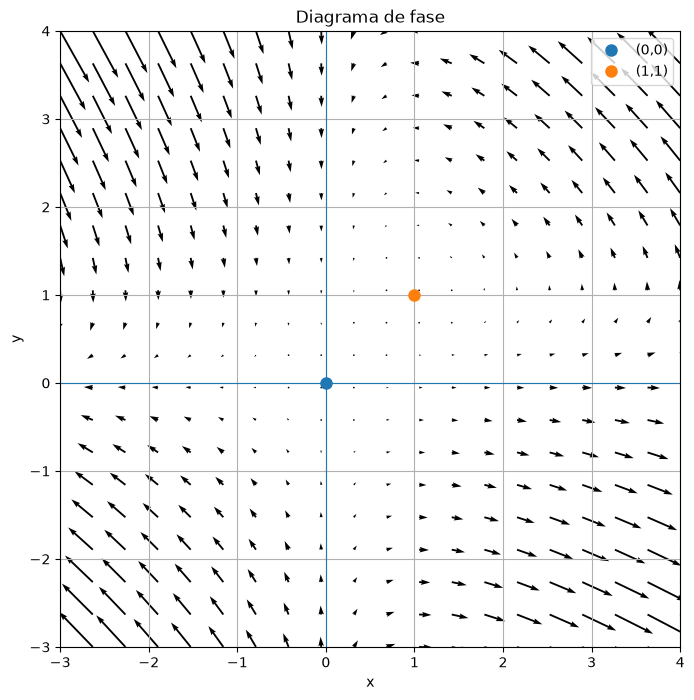

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Valores de los parámetros
# --------------------------------------------------

a = 1
b = 1
c = 1
d = 1

# --------------------------------------------------
# Puntos críticos
# --------------------------------------------------

P1 = (0, 0)
P2 = (c/d, a/b)

print("Puntos críticos:")
print("P1 =", P1)
print("P2 =", P2)

# --------------------------------------------------
# Mallado del plano
# --------------------------------------------------

x = np.linspace(-3, 4, 20)
y = np.linspace(-3, 4, 20)

xg, yg = np.meshgrid(x, y)

# --------------------------------------------------
# Campo vectorial
# --------------------------------------------------

u = xg * (a - b * yg)
v = yg * (-c + d * xg)

# --------------------------------------------------
# Diagrama de fase
# --------------------------------------------------

plt.figure(figsize=(8, 8))

plt.quiver(xg, yg, u, v)

# Marcar puntos críticos
plt.plot(P1[0], P1[1], 'o', markersize=8, label='(0,0)')
plt.plot(P2[0], P2[1], 'o', markersize=8, label='(1,1)')

# Ejes
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel('x')
plt.ylabel('y')
plt.title('Diagrama de fase')

plt.xlim(-3, 4)
plt.ylim(-3, 4)

plt.grid()
plt.legend()

plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --------------------------------------------------
# Parámetros
# --------------------------------------------------

a = 1
b = 1
c = 1
d = 1

# --------------------------------------------------
# Sistema de ecuaciones
# --------------------------------------------------

def sistema(t, X):
    x, y = X
    
    dxdt = x * (a - b*y)
    dydt = y * (-c + d*x)
    
    return [dxdt, dydt]

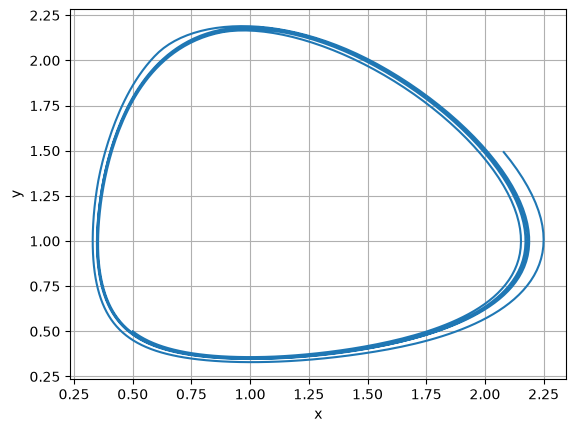

In [2]:
X0 = [0.5, 0.5]

t_span = (0, 30)

sol = solve_ivp(
    sistema,
    t_span,
    X0,
    t_eval=np.linspace(0, 30, 1000)
)

plt.plot(sol.y[0], sol.y[1])

plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.show()